# 03. greedy 선택의 안전장치 — 최소 개선과 group fold

[02 greedy ensemble selection](02_greedy_ensemble_selection.ipynb)은 out-of-fold 손실이 조금이라도 낮은 조합을 고릅니다. 그래서 두 가지 경우에 손해를 봤습니다. 하나는 out-of-fold 손실의 노이즈에 맞춰 너무 낮은 온도를 고르는 경우이고(02의 wine split 0, BeyondArena의 mice_protein), 다른 하나는 test가 학습 행과 다른 group에서 오는데 out-of-fold는 무작위로 나눈 경우입니다(BeyondArena의 grouped split). 이 저장소는 이것을 막는 옵션 세 개를 더했습니다(issue #52, PR #58). 논문에는 없는 것입니다.

| 옵션 | 하는 일 | 기본값 |
|---|---|---|
| `min_improvement` | 고른 조합이 out-of-fold에서 기본보다 충분히 낫지 않으면 기본 앙상블을 쓴다 | 켬 (1%, 분류는 1e-3 nats도) |
| `min_temperature` | 이보다 낮은 온도를 후보에서 뺀다 | 끔 |
| `fit(X, y, groups=...)` | out-of-fold를 group 단위로 나눈다 | 평가 스크립트는 task의 split 방식을 따른다 |

다루는 흐름:

1. 최소 개선 — 언제 기본 앙상블로 되돌리나
2. 온도 하한 — 02의 wine split 0
3. group fold — test가 처음 보는 group일 때
4. 큰 benchmark에서는
5. 정리

## `minipfn` 불러오기

다른 노트북과 같은 import shim입니다. 이 노트북은 `notebooks/topics_inference/` 아래에 있으므로 저장소 루트는 두 단계 위입니다. 2·3절은 Hub에서 v2 분류 가중치(`aiden-jeon/minipfn-tabpfn-v2-classifier`)를 받습니다. 3절은 CPU에서 2분쯤 걸립니다.

In [1]:
try:
    import minipfn
except ImportError:
    import sys
    from pathlib import Path

    sys.path.insert(0, str(Path.cwd().parents[1] / "src"))
    import minipfn

In [2]:
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.datasets import load_wine
from sklearn.metrics import log_loss
from sklearn.model_selection import (
    GroupShuffleSplit,
    StratifiedGroupKFold,
    StratifiedKFold,
    train_test_split,
)

from minipfn import TabPFNv2Classifier, set_seed
from minipfn.inference import ensemble_selection as es

set_seed(0)  # 재현성을 위해 난수 시드를 고정한다.
warnings.filterwarnings("ignore", category=UserWarning)  # sklearn 변환기의 경고

## 1. 최소 개선 — 언제 기본 앙상블로 되돌리나

규칙은 하나입니다. greedy가 고른 조합의 out-of-fold 손실이 기본 앙상블(후보 0번)보다 `MIN_IMPROVEMENT`(1%) 이상 낮아야 고른 것을 쓰고, 아니면 기본 앙상블을 그대로 씁니다. 분류는 log loss가 `MIN_IMPROVEMENT_NATS`(0.001) 이상 낮아야 한다는 조건이 하나 더 있습니다. 기본 손실이 거의 0이면 아주 작은 차이도 비율로는 크게 보이기 때문입니다.

후보가 둘(0번 기본, 1번 greedy가 고른 조합)뿐인 out-of-fold 예측을 손으로 만들어 세 경우를 봅니다. 행마다 정답 클래스에 준 확률을 똑같이 두면, log loss는 $-\log p$ 하나로 정해집니다.

In [3]:
selector = es.GreedyEnsembleClassifier(TabPFNv2Classifier().model, n_estimators=4)

cases = {
    "거의 같음": (0.300, 0.298),
    "기본이 이미 거의 0 (mice_protein처럼)": (0.0008, 0.0002),
    "크게 낮음 (02의 wine split 0)": (0.053, 0.013),
}
guard_rows = []
for name, (default_loss, selected_loss) in cases.items():
    # 후보 2개 × 행 100개: 정답 클래스 확률 = exp(-손실)
    oof = np.stack([np.full(100, np.exp(-default_loss)), np.full(100, np.exp(-selected_loss))])
    greedy_pick = np.array([0.0, 1.0])  # greedy는 1번에 가중치를 모두 주었다
    weights, reverted = selector._guard(greedy_pick, oof, es._log_loss)
    guard_rows.append(
        {
            "경우": name,
            "기본 OOF": default_loss,
            "고른 것 OOF": selected_loss,
            "비율로 줄어듦": 1 - selected_loss / default_loss,
            "nats로 줄어듦": default_loss - selected_loss,
            "결과": "기본으로 되돌림" if reverted else "고른 것을 씀",
        }
    )
display(pd.DataFrame(guard_rows).set_index("경우").round(4))

,기본 OOF,고른 것 OOF,비율로 줄어듦,nats로 줄어듦,결과
경우,,,,,
거의 같음,0.3000,0.2980,0.0067,0.0020,기본으로 되돌림
기본이 이미 거의 0 (mice_protein처럼),0.0008,0.0002,0.7500,0.0006,기본으로 되돌림
크게 낮음 (02의 wine split 0),0.0530,0.0130,0.7547,0.0400,고른 것을 씀


첫째 경우는 0.7%만 줄어 1%에 못 미치고, 둘째는 비율로는 75%나 줄었지만 차이가 0.0006 nats라 0.001에 못 미쳐 둘 다 기본으로 되돌립니다. BeyondArena의 mice_protein이 둘째 경우였습니다. 기본 out-of-fold 손실이 거의 0인데 greedy가 멤버 하나를 온도 0.25로 골라 test log loss가 1.14에서 4.8쯤이 되었고, 이 guard를 켜자 1.14로 돌아왔습니다.

셋째 경우인 02의 wine split 0은 out-of-fold에서 0.04 nats, 75%나 줄었으므로 guard가 막지 못합니다. out-of-fold에서 보기에는 정말로 나아졌기 때문입니다. guard는 "out-of-fold로 봐도 확실하지 않은 이득"만 거릅니다.

## 2. 온도 하한 — 02의 wine split 0

wine split 0에서 greedy는 가중치를 모두 온도 0.25에 주었습니다. 온도가 0.5보다 낮은 후보를 빼면(`min_temperature=0.5`) 어떻게 되는지 잽니다. 02와 같은 split입니다.

In [4]:
model = selector.model
x_wine, y_wine = load_wine(return_X_y=True)
x_tr, x_te, y_tr, y_te = train_test_split(
    x_wine, y_wine, test_size=0.5, random_state=0, stratify=y_wine
)

floor_rows = {}
default_proba = TabPFNv2Classifier(model, n_estimators=4).fit(x_tr, y_tr).predict_proba(x_te)
floor_rows["기본 앙상블"] = {"test log loss": log_loss(y_te, default_proba)}
settings = {
    "greedy (논문 방식)": {"min_improvement": 0.0},
    "greedy + 최소 개선 (기본값)": {},
    "greedy + 최소 개선 + 온도 하한 0.5": {"min_temperature": 0.5},
}
for name, kwargs in settings.items():
    sel = es.GreedyEnsembleClassifier(model, n_estimators=4, **kwargs).fit(x_tr, y_tr)
    temperatures = sorted({t for member in sel.member_weights_ for t in member})
    floor_rows[name] = {
        "test log loss": log_loss(y_te, sel.predict_proba(x_te)),
        "OOF (기본)": sel.selection_["oof_loss_default"],
        "OOF (고른 것)": sel.selection_["oof_loss_selected"],
        "되돌림": sel.selection_["reverted"],
        "쓴 온도": str(temperatures),
    }
display(pd.DataFrame(floor_rows).T)

,test log loss,OOF (기본),OOF (고른 것),되돌림,쓴 온도
기본 앙상블,0.05116,NaN,NaN,NaN,NaN
greedy (논문 방식),0.152939,0.053369,0.01309,False,[0.25]
greedy + 최소 개선 (기본값),0.152939,0.053369,0.01309,False,[0.25]
greedy + 최소 개선 + 온도 하한 0.5,0.094625,0.053369,0.019728,False,[0.5]


온도 하한을 두면 greedy가 온도 0.5를 골라 test 손실이 0.153에서 0.095로 줄지만, 기본 앙상블(0.051)보다는 여전히 나쁩니다. out-of-fold에서 그다음으로 날카로운 온도를 고른 것뿐입니다. 하한을 어디에 두든 out-of-fold의 노이즈에 맞추는 일은 그대로 남습니다. 4절에서 보듯 benchmark에서도 온도 하한은 이득이 없었습니다.

## 3. group fold — test가 처음 보는 group일 때

동네 가게 30곳의 열흘 치 기록으로 표를 만듭니다. 행 하나는 가게 하나의 하루이고, feature는 그날의 손님 수 변화(`visitors`)와 가게 특성 세 개(넓이, 주차 자리, 역까지 거리를 표준화한 값)입니다. 가게 특성은 그 가게의 모든 행에서 거의 같습니다. 정답은 그날 하루 매출 목표를 넘었는지(1) 아닌지(0)이고, 손님 수와 함께 가게마다 다른 경향(어떤 가게는 거의 늘 넘고, 어떤 가게는 거의 못 넘음)이 크게 좌우합니다.

test는 학습 행에 없던 가게 15곳입니다. 새 가게를 열기 전에 목표를 넘을지 예측하는 상황입니다.

In [5]:
def make_shops(seed, n_shops=30, days=10):
    rng = np.random.default_rng(seed)
    shop = np.repeat(np.arange(n_shops), days)  # 행마다 가게 번호
    traits = rng.normal(size=(n_shops, 3))  # 가게 특성: 가게 안에서 같다
    tendency = rng.normal(scale=3.0, size=n_shops)  # 가게마다 다른 경향
    visitors = rng.normal(size=len(shop))  # 그날의 손님 수 변화
    measured = traits[shop] + rng.normal(scale=0.02, size=(len(shop), 3))  # 잴 때마다 조금 다르다
    x = np.column_stack([visitors, measured])
    p_hit = 1 / (1 + np.exp(-(visitors + tendency[shop])))
    y = (rng.random(len(shop)) < p_hit).astype(int)
    return x, y, shop


x, y, shop = make_shops(0)
preview = pd.DataFrame(x, columns=["visitors", "area", "parking", "station"]).round(2)
preview.insert(0, "가게", shop)
preview["목표 넘음"] = y
display(preview[preview["가게"].isin([0, 1])].head(6))
display(preview[preview["가게"].isin([0, 1])].tail(3))

,가게,visitors,area,parking,station,목표 넘음
0,0,0.79,0.10,-0.10,0.66,0
1,0,0.84,0.12,-0.09,0.63,1
2,0,0.08,0.10,-0.14,0.66,0
3,0,-1.43,0.11,-0.09,0.62,1
4,0,-0.14,0.14,-0.12,0.64,1
5,0,-0.77,0.15,-0.16,0.67,0


,가게,visitors,area,parking,station,목표 넘음
17,1,1.15,0.09,-0.54,0.39,1
18,1,-2.37,0.11,-0.51,0.35,1
19,1,1.23,0.10,-0.61,0.37,1


가게 0은 목표를 넘은 날과 못 넘은 날이 섞여 있지만, 가게 1은 손님이 크게 줄어든 날(visitors −2.37)에도 목표를 넘었습니다. 가게 특성 세 열(area, parking, station)은 가게 안에서 거의 같아서, 이 세 열만 보면 어느 가게의 행인지 알 수 있습니다. 그래서 무작위로 out-of-fold를 나누면, 검증하는 행과 같은 가게의 다른 날이 context에 들어 있어 모델이 "이 가게는 늘 넘더라"를 보고 맞힙니다. test에서는 그 가게를 처음 봅니다.

같은 기본 앙상블의 손실을 세 가지로 잽니다. 무작위 8-fold out-of-fold, 가게 단위 8-fold out-of-fold(한 가게의 행은 한 fold에만), 그리고 처음 보는 가게 15곳의 test입니다. 데이터를 다섯 번 새로 만듭니다.

In [6]:
def oof_log_loss(x, y, splits):
    proba = np.zeros((len(y), 2))
    for fit_rows, held_out_rows in splits:
        clf = TabPFNv2Classifier(model, n_estimators=4).fit(x[fit_rows], y[fit_rows])
        proba[held_out_rows] = clf.predict_proba(x[held_out_rows])
    return log_loss(y, proba)


shop_data = []
estimate_rows = []
for seed in range(5):
    x, y, shop = make_shops(seed)
    splitter = GroupShuffleSplit(1, test_size=0.5, random_state=seed)  # 가게 절반은 test
    train_rows, test_rows = next(splitter.split(x, y, shop))
    x_tr, y_tr, shop_tr = x[train_rows], y[train_rows], shop[train_rows]
    x_te, y_te = x[test_rows], y[test_rows]
    shop_data.append((x_tr, y_tr, shop_tr, x_te, y_te))

    random_folds = StratifiedKFold(es.N_FOLDS, shuffle=True, random_state=0)
    shop_folds = StratifiedGroupKFold(es.N_FOLDS, shuffle=True, random_state=0)
    clf = TabPFNv2Classifier(model, n_estimators=4).fit(x_tr, y_tr)
    estimate_rows.append(
        {
            "데이터": seed,
            "무작위 fold OOF": oof_log_loss(x_tr, y_tr, random_folds.split(x_tr, y_tr)),
            "가게 단위 fold OOF": oof_log_loss(x_tr, y_tr, shop_folds.split(x_tr, y_tr, shop_tr)),
            "test (처음 보는 가게)": log_loss(y_te, clf.predict_proba(x_te)),
        }
    )
estimates = pd.DataFrame(estimate_rows).set_index("데이터")
display(estimates.round(3))

,무작위 fold OOF,가게 단위 fold OOF,test (처음 보는 가게)
데이터,,,
0,0.544,0.841,0.859
1,0.424,0.657,0.783
2,0.432,0.711,0.831
3,0.434,0.691,0.775
4,0.485,0.944,0.663


무작위 fold의 out-of-fold 손실은 다섯 번 모두 test보다 0.18~0.40 낮습니다. 같은 가게의 다른 날을 보고 맞힌 만큼 낙관적입니다. 가게 단위 fold는 test에 훨씬 가깝습니다(넷은 0.13 안쪽이고, 데이터 4는 0.28 높습니다). 학습 행의 가게가 15곳뿐이라 fold마다 가게가 두 곳 남짓이어서 이 추정도 흔들리지만, 무작위 fold처럼 늘 한쪽으로 치우치지는 않습니다.

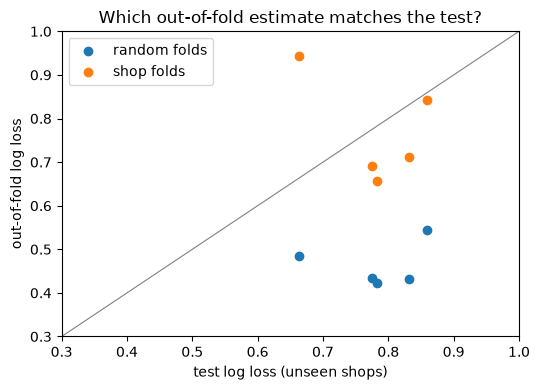

In [7]:
fig, ax = plt.subplots(figsize=(5.5, 4))
ax.scatter(estimates["test (처음 보는 가게)"], estimates["무작위 fold OOF"], label="random folds")
ax.scatter(estimates["test (처음 보는 가게)"], estimates["가게 단위 fold OOF"], label="shop folds")
lims = [0.3, 1.0]
ax.plot(lims, lims, color="gray", lw=0.8)
ax.set_xlim(lims)
ax.set_ylim(lims)
ax.set_xlabel("test log loss (unseen shops)")
ax.set_ylabel("out-of-fold log loss")
ax.set_title("Which out-of-fold estimate matches the test?")
ax.legend()
plt.tight_layout()
plt.show()

greedy는 이 out-of-fold 손실로 후보를 고릅니다. `fit(x, y, groups=shop)`으로 가게 번호를 주면 out-of-fold를 가게 단위로 나눕니다. 같은 다섯 데이터에서 test 손실을 견줍니다. 여기서는 최소 개선을 끄고 fold만 바꿉니다.

In [8]:
greedy_rows = []
for seed, (x_tr, y_tr, shop_tr, x_te, y_te) in enumerate(shop_data):
    default = TabPFNv2Classifier(model, n_estimators=4).fit(x_tr, y_tr)
    row = {"데이터": seed, "기본 앙상블": log_loss(y_te, default.predict_proba(x_te))}
    for name, groups in [("greedy, 무작위 fold", None), ("greedy, 가게 단위 fold", shop_tr)]:
        sel = es.GreedyEnsembleClassifier(model, n_estimators=4, min_improvement=0.0)
        sel.fit(x_tr, y_tr, groups=groups)
        row[name] = log_loss(y_te, sel.predict_proba(x_te))
    greedy_rows.append(row)
greedy_table = pd.DataFrame(greedy_rows).set_index("데이터")
greedy_table.loc["평균"] = greedy_table.mean()
display(greedy_table.round(3))

,기본 앙상블,"greedy, 무작위 fold","greedy, 가게 단위 fold"
데이터,,,
0,0.859,0.877,0.774
1,0.783,0.805,0.993
2,0.831,0.812,0.831
3,0.775,0.904,0.926
4,0.663,0.670,0.692
평균,0.782,0.814,0.843


이 작은 예에서는 가게 단위 fold로 고른 greedy가 데이터 0에서만 기본보다 나았고, 평균은 오히려 가장 나빴습니다(0.843). 학습 행이 150개, 가게가 15곳뿐이라 가게 단위 out-of-fold 손실은 test와 같은 것을 재는 대신 노이즈가 크고, 02에서 본 것처럼 후보 217개 가운데 그 노이즈에 맞는 것을 고르게 됩니다. 무작위 fold로 고른 greedy도 평균으로 기본보다 나빴습니다(0.814). fold를 바르게 나누면 무엇을 재는지는 바로잡히지만, 얼마나 정확히 재는지는 데이터 크기가 정합니다. 그래서 효과는 데이터셋이 많은 benchmark에서 판정했습니다.

## 4. 큰 benchmark에서는

v2 공개 가중치로 BeyondArena-lite(78개 split, 그 가운데 grouped 8개·temporal 4개)와 TabArena-Lite에서 쟀습니다(PR #58). 평가 스크립트의 `--oof-split task`는 split 방식이 grouped면 TabArena가 주는 group 열로, temporal이면 시간 열을 행 수가 비슷한 구간 8개로 나눠 group을 만듭니다(`minipfn.benchmarks.arena.split_groups`). 무작위 split이면 group을 주지 않습니다.

| | BeyondArena-lite Elo | 그 가운데 grouped split | mice_protein log loss | split마다 가장 크게 나빠진 비율 (기본 대비) | TabArena-Lite Elo |
|---|---|---|---|---|---|
| 기본 앙상블 | 1028 | 1080 | 1.14 | — | 1221 |
| greedy (논문 방식) | 1029 | 1023 | 4.83 | +324% | 1260 |
| + 최소 개선 | 1032 | 1054 | 1.14 | | 1261 |
| + 온도 하한 0.5 | 1031 | 1022 | 2.63 | | 1261 |
| + group fold | 1042 | 1096 | 0.93 | | |
| 셋 다 | 1043 | 1102 | | +8% | 1260 |

group fold가 grouped split의 손해를 가장 많이 되돌렸고(1023 → 1096), 최소 개선은 mice_protein 같은 큰 실패를 막았습니다. 셋을 다 켜면 가장 크게 나빠진 split이 +324%에서 +8%로 줄었습니다. TabArena-Lite에는 group 열이나 시간 열이 있는 task가 없어서 group fold가 아무것도 바꾸지 않고, 점수도 그대로였습니다. 온도 하한은 이득이 없어 기본으로 끄고 둡니다. 그래서 저장소의 기본값은 최소 개선 1% 켬, 평가 스크립트 `--oof-split task`, 온도 하한 끔입니다. `--min-improvement 0 --oof-split random`으로 주면 논문 방식 그대로입니다.

## 5. 정리

| 실패 | 왜 생기나 | 막는 장치 | 이 노트북 |
|---|---|---|---|
| 기본 out-of-fold 손실이 거의 0인데 날카로운 온도를 고름 | 아주 작은 차이도 비율로는 커 보인다 | 최소 개선(1%와 0.001 nats) | 1절 |
| 작은 데이터에서 out-of-fold 노이즈에 맞춘 낮은 온도 | out-of-fold로 보기에도 정말 나아졌다 | 온도 하한이 막지만, benchmark에서 이득이 없어 끔 | 2절 |
| test가 처음 보는 group | 무작위 fold는 같은 group의 다른 행을 context에 둔다 | group fold (`fit(groups=)`, `--oof-split task`) | 3절 |

- guard는 out-of-fold로 봐도 확실하지 않은 이득만 거릅니다. out-of-fold 자체가 test를 잘못 비추면 fold를 test와 같은 방식으로 나눠야 합니다.
- 작은 데이터 몇 개로는 이 방법들의 효과를 판정할 수 없습니다. 판정은 4절처럼 benchmark의 Elo와 split마다 가장 나쁜 경우로 했습니다.